In [1]:
import geopandas as gpd
import osmnx as ox
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"
NOTEBOOK_PATH

PosixPath('/home/jovyan/my-work/practical4')

In [2]:
# 1. Luetaan shapefile GeoDataFrameksi GeoPandasilla
gdf = gpd.read_file(DATA_DIRECTORY/"aluerajaus"/"aluerajaus.shp")

# Varmistetaan, että koordinaattijärjestelmä (CRS) on WGS84 (EPSG:4326),
# sillä OSMnx vaatii maantieteelliset pituus- ja leveyskoordinaatit.
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# 2. Haetaan alueen polygon-geometria (esim. ensimmäinen rivi)
alue_polygon = gdf.geometry.iloc[0]

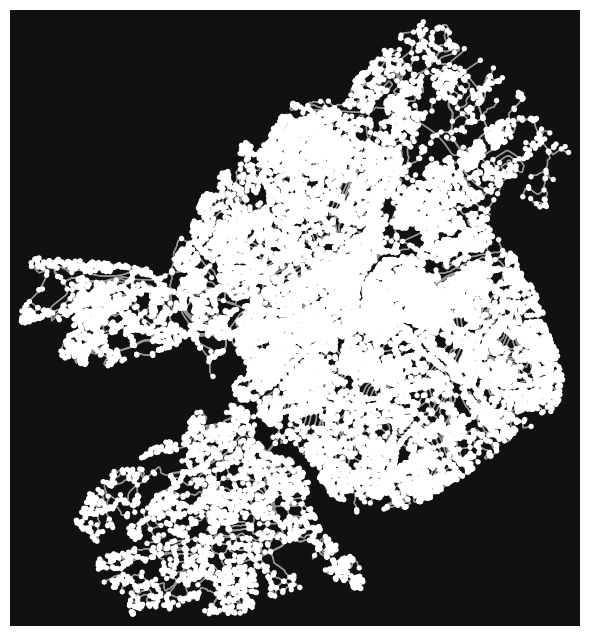

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [3]:
# 3. Ladataan katuverkko OpenStreetMapista polygonin sisältä
G = ox.graph_from_polygon(alue_polygon, network_type="bike")

# 4. Visualisoidaan ladattu graafi
ox.plot_graph(G)

In [4]:
nodes, edges = ox.graph_to_gdfs(G)

<Axes: >

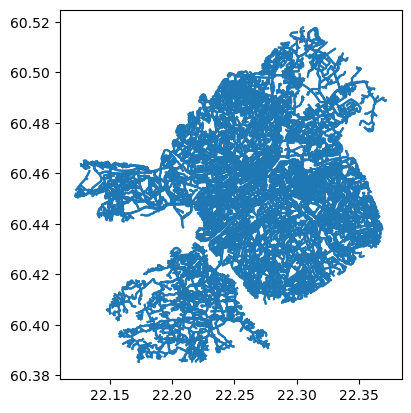

In [5]:
edges.plot()

In [6]:
edges.head()

osmid      highway lanes maxspeed  \
u      v           key                                           
224093 13313453370 0     762126626    secondary     2       50   
224097 5272039635  0    1319665346     tertiary     2       50   
       166809249   0    1367320076      primary     1       50   
       1616825494  0    1428240611     tertiary     2       50   
224101 530809840   0    1116911838  residential     2       30   

                                   name  oneway reversed     length  \
u      v           key                                                
224093 13313453370 0      Tukholmankatu    True    False   8.702840   
224097 5272039635  0         Linnankatu   False     True   9.664226   
       166809249   0    Vallihaudankatu    True    False  57.252128   
       1616825494  0         Linnankatu   False    False  46.373220   
224101 530809840   0      Fleminginkatu   False     True  12.887189   

                                                                 geometry  \
u      v           key                                                      
224093 13313453370 0    LINESTRING (22.23224 60.44427, 22.23208 60.44427)   
224097 5272039635  0    LINESTRING (22.23096 60.43589, 22.23111 60.43594)   
       166809249   0    LINESTRING (22.23096 60.43589, 22.23113 60.435...   
       1616825494  0    LINESTRING (22.23096 60.43589, 22.23079 60.435...   
224101 530809840   0    LINESTRING (22.23461 60.43712, 22.23448 60.43721)   

                        ref bridge service access width tunnel junction area  \
u      v           key                                                         
224093 13313453370 0    NaN    NaN     NaN    NaN   NaN    NaN      NaN  NaN   
224097 5272039635  0    NaN    NaN     NaN    NaN   NaN    NaN      NaN  NaN   
       166809249   0    NaN    NaN     NaN    NaN   NaN    NaN      NaN  NaN   
       1616825494  0    NaN    NaN     NaN    NaN   NaN    NaN      NaN  NaN   
224101 530809840   0    NaN    NaN     NaN    NaN   NaN    NaN      NaN  NaN   

                       est_width  
u      v           key            
224093 13313453370 0         NaN  
224097 5272039635  0         NaN  
       166809249   0         NaN  
       1616825494  0         NaN  
224101 530809840   0         NaN

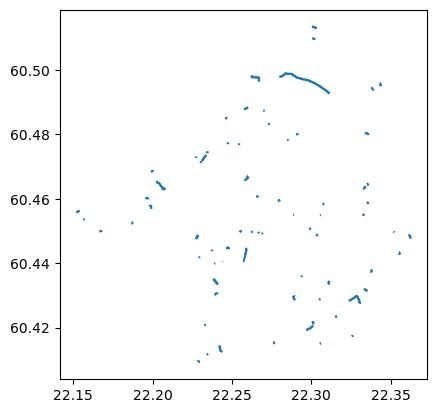

In [7]:
#tunnelit = edges[edges["tunnel"]!="NaN"]
edges.sort_values("tunnel")
tunnelit = edges["tunnel"].unique()
edges_tunnels = edges.loc[edges["tunnel"].isin(["yes", "covered"])]
edges_tunnels.head()
edges_tunnels.plot()
edges_tunnels.explore()

In [8]:
import osmnx as ox

# Download paths and roads with tunnel tags
tunnels = ox.features_from_place(
    "Turku, Finland",
    tags={"tunnel": True}
)

# Keep cycling and pedestrian infrastructure
underpasses = tunnels[
    tunnels["highway"].isin([
        "cycleway",
        "footway",
        "path",
        "pedestrian"
    ])
].copy()

# Keep relevant attributes
columns = [
    col for col in
    ["highway", "tunnel", "layer", "bicycle", "foot", "geometry"]
    if col in underpasses.columns
]

underpasses = underpasses[columns]

# Display the result
underpasses.explore()

<Axes: >

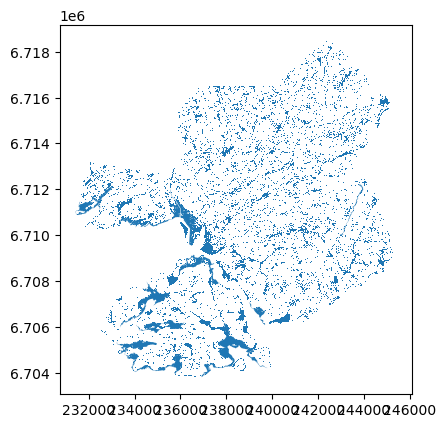

In [9]:
tulvat=gpd.read_file(DATA_DIRECTORY/"tulva_kohtalainen"/"Tulva_kohtalainen.shp")
tulvat.plot()